# S1-02 · 人形接近与操作（oracle 版）｜SceneFun3D 场景 421069

**这一步回答：** 用 S1-01 算出的可执行 affordance（接触点、支撑面法向、站立点、朝向、运动轴），能不能摆出一个"位置准、动作对"的人形？

| | 内容 |
|---|---|
| 输入 | S1-01 的 `runs/mem_s1/actionable_oracle.json` 与各关键帧的输入相机和深度；部件位置与运动轴仍是 oracle |
| 人形 | SMPL-X 中性体型；站立或下蹲（接触点离地低于 0.55 m）；面向部件，双脚落在输入估计的地面上，再用 IK 让手掌（foot_push 为右脚）到达接触点 |
| 画面 | **主画面**：贴在关键帧上，按输入深度做遮挡；**检查画面**：放进激光扫描（只用于评测），洋红色为真值部件 |
| 指标 | IK 残差；手掌／脚到真值部件的距离；双脚离真实地面的高度；身体与扫描冲突的顶点比例（不含手／脚附近） |
| 许可 | SMPL-X 模型文件只在本地 `data/body_models/` 使用，notebook 里只保存渲染图，不保存网格 |

运行前先执行 [S1-01](S1_01_video_inputs_to_actionable_affordance.ipynb)。

## Step 0 · 参数与数据

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open3d as o3d
import pandas as pd
from IPython.display import display
from scipy.spatial import cKDTree

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "affordance3d").is_dir())
sys.path.insert(0, str(ROOT))

from affordance3d.frames import Frame
from affordance3d.geometry import project
from affordance3d.mem.body import JOINT, load_smplx
from affordance3d.mem.depth_models import MonoDepth
from affordance3d.mem.humanoid import pose_humanoid
from affordance3d.mem.inputs import index_video
from affordance3d.mem.render import look_at, overlay_body, rasterize, splat, to_camera
from affordance3d.scenefun3d import read_annotations, read_laser_scan

%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams.update({"figure.dpi": 90, "savefig.dpi": 90, "font.size": 9, "axes.unicode_minus": False,
                     "font.sans-serif": ["PingFang SC", "Heiti SC", "Arial Unicode MS", "DejaVu Sans"]})

DATA = ROOT / "data" / "scenefun3d"
VISIT, VIDEO = "421069", "42444490"
S1 = ROOT / "runs" / "mem_s1"
MODEL_PATH = ROOT / "data" / "body_models" / "smplx" / "SMPLX_NEUTRAL.npz"
PIXEL_STEP = 2
COLLISION_M, NEAR_EFFECTOR_M = 0.02, 0.15
VISIBLE_DEPTH_M = 0.15  # the contact counts as visible in a frame when the input depth agrees within this
CANDIDATE_STRIDE = 3  # display frames are searched over every 3rd video frame, not only the keyframes

records = json.loads((S1 / "actionable_oracle.json").read_text())
manifest = json.loads((S1 / "manifest.json").read_text())
UP, FLOOR = np.array(manifest["up_input"]), manifest["floor_input"]
keyframes = manifest["keyframes"]
vid = index_video(DATA, VISIT, VIDEO)
body_model = load_smplx(MODEL_PATH)


arkit_to_faro = np.linalg.inv(vid.faro_to_arkit)
HALF_HW = (1920 // PIXEL_STEP, 1440 // PIXEL_STEP)


def camera(t: str) -> tuple[np.ndarray, np.ndarray]:
    # Input camera of any video frame: hires intrinsics (subsampled) and the ARKit pose, expressed in the Faro frame.
    return np.diag([1 / PIXEL_STEP, 1 / PIXEL_STEP, 1.0]) @ vid.intrinsics(t), arkit_to_faro @ vid.arkit_pose(t)
scan_xyz, scan_rgb = read_laser_scan(DATA / VISIT / f"{VISIT}_laser_scan.ply")
crop = np.load(DATA / VISIT / f"{VISIT}_crop_mask.npy")
cloud = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(scan_xyz[crop]))
cloud.colors = o3d.utility.Vector3dVector(scan_rgb[crop].astype(np.float64))
cloud = cloud.voxel_down_sample(0.01)
scan_cm, scan_cm_rgb = np.asarray(cloud.points), np.asarray(cloud.colors)
scan_tree = cKDTree(scan_cm)
part_points = {e.annot_id: scan_xyz[e.indices] for e in read_annotations(DATA / VISIT / f"{VISIT}_annotations.json")}
print(f"{len(records)} 个可执行 affordance；深度 {manifest['mono_model']}；SMPL-X: {MODEL_PATH.relative_to(ROOT)}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


29 个可执行 affordance；深度 DA-V2 L × LiDAR 尺度；SMPL-X: data/body_models/smplx/SMPLX_NEUTRAL.npz


## Step 1 · 每类动作选一个部件，并选一个适合展示的视频帧

展示帧在**整段视频**（每 3 帧取 1）里找，只用输入：接触点在画面内且可见（LiDAR 深度与接触点深度一致），站立处的身体（脚、腰、头三个点）尽量都在画面内，相机离接触点 1.5–4 m。选中的帧再用 S1-01 选出的单目深度算一次深度，用于遮挡。

In [2]:
candidates = vid.rgb_times[::CANDIDATE_STRIDE]
cameras = {t: camera(t) for t in candidates}


def display_score(record: dict, t: str) -> tuple[float, int]:
    intrinsics, pose = cameras[t]
    frame = Frame(0, np.zeros((1, 1, 3), np.uint8), np.zeros(HALF_HW, np.float32), intrinsics, pose)
    contact, stand = np.array(record["contact_faro"]), np.array(record["stand_faro"])
    uv, z, inside = project(np.vstack([contact, stand + np.outer([0.1, 0.9, 1.6], UP)]), frame)
    if not inside[0]:
        return -1.0, 0
    u, v = np.rint(uv[0]).astype(int)
    observed = vid.lidar_depth(t, HALF_HW)[v, u]
    if observed <= 0 or abs(observed - z[0]) > VISIBLE_DEPTH_M:
        return -1.0, 0
    distance = np.linalg.norm(contact - pose[:3, 3])
    in_view = int(inside[1:].sum())
    return in_view + (1.0 if 1.5 <= distance <= 4.0 else 0.0) - 0.1 * abs(distance - 2.5), in_view


examples = []
for action in sorted({r["action"] for r in records}):
    best = max((r for r in records if r["action"] == action), key=lambda r: r["pixels"])
    scores = {t: display_score(best, t) for t in candidates}
    shown = max(scores, key=lambda t: scores[t][0])
    examples.append({**best, "display_frame": shown, "body_points_in_view": scores[shown][1]})

mono = MonoDepth(manifest["mono_model_id"])
frames = {}
for e in examples:
    t = e["display_frame"]
    if t in frames:
        continue
    rgb = plt.imread(vid.rgb_path(t))
    depth = mono.predict(rgb, focal_px=float(vid.intrinsics(t)[0, 0]))[::PIXEL_STEP, ::PIXEL_STEP]
    if manifest["lidar_scaled"]:
        lidar = vid.lidar_depth(t, HALF_HW)
        both = (lidar > 0) & (depth > 0)
        depth = depth * np.median(lidar[both] / depth[both])
    intrinsics, pose = cameras[t]
    frames[t] = Frame(0, rgb[::PIXEL_STEP, ::PIXEL_STEP], depth.astype(np.float32), intrinsics, pose)
del mono
display(pd.DataFrame([{"动作": e["action"], "任务": e["task"] or "（无描述）", "部件像素": e["pixels"],
                       "标签所在关键帧": e["keyframe"], "展示帧": e["display_frame"],
                       "身体点在画面内（脚/腰/头）": e["body_points_in_view"]} for e in examples]))

W1110 13:38:50.681000 48896 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/503 [00:00<?, ?it/s]

/opt/anaconda3/envs/affordance3d/lib/python3.12/site-packages/transformers/image_processing_backends.py:135: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:214.)
  image = torch.from_numpy(image)


,动作,任务,部件像素,标签所在关键帧,展示帧,身体点在画面内（脚/腰/头）
0,foot_push,Open the trash can located in the kitchen near...,1009,1267.272,1264.273,2
1,hook_pull,Open the top oven door,832,1282.166,1304.174,3
2,hook_turn,Open the small window located near to the port...,173,1254.177,1253.478,1
3,key_press,Turn on the TV using the remote control locate...,516,1321.167,1316.769,1
4,plug_in,Plug the device in the power supply located ne...,88,1264.673,1263.973,3
5,rotate,（无描述）,212,1282.166,1303.874,3
6,tip_push,Turn on the floor lamp next to the couch,54,1331.679,1327.381,3


## Step 2 · 摆人形：面向部件、双脚着地、IK 到接触点

In [3]:
gt_floor = manifest["gt_floor"]


def effector_position(human) -> np.ndarray:
    if human.effector == "right foot":
        return human.joints[JOINT["right_foot"]]
    side = human.effector.split()[0]
    return 0.5 * (human.joints[JOINT[f"{side}_wrist"]] + human.joints[JOINT[f"{side}_middle1"]])


posed, rows = [], []
for e in examples:
    human = pose_humanoid(body_model, np.array(e["contact_faro"]), np.array(e["normal_faro"]), np.array(e["stand_faro"]),
                          np.array(e["facing_faro"]), FLOOR, UP, e["action"])
    near_effector = np.linalg.norm(human.vertices - human.target, axis=1) < NEAR_EFFECTOR_M
    distances, _ = scan_tree.query(human.vertices[~near_effector])
    effector = effector_position(human)
    posed.append(human)
    rows.append({"动作": e["action"], "末端": human.effector, "姿态": human.posture,
                 "IK 残差 cm": 100 * human.reach_error_m,
                 "手掌/脚到真值部件 cm": 100 * np.min(np.linalg.norm(part_points[e["annot_id"]] - effector, axis=1)),
                 "双脚离真实地面 cm": 100 * (human.vertices[:, 2].min() - gt_floor),
                 "身体与扫描冲突": float(np.mean(distances < COLLISION_M)),
                 "站立点在扫描中空闲": e["stand_free_in_scan"]})
humanoid_table = pd.DataFrame(rows)
display(humanoid_table.style.format({"IK 残差 cm": "{:.1f}", "手掌/脚到真值部件 cm": "{:.1f}",
                                     "双脚离真实地面 cm": "{:+.1f}", "身体与扫描冲突": "{:.1%}"}).hide(axis="index"))

动作,末端,姿态,IK 残差 cm,手掌/脚到真值部件 cm,双脚离真实地面 cm,身体与扫描冲突,站立点在扫描中空闲
foot_push,right foot,standing,4.0,5.5,+4.7,0.0%,True
hook_pull,right hand,standing,4.3,1.7,+3.6,0.0%,True
hook_turn,right hand,standing,3.5,4.0,+5.7,1.1%,True
key_press,right hand,squatting,0.5,5.7,+3.4,2.9%,False
plug_in,right hand,standing,7.1,21.0,+3.9,0.0%,True
rotate,right hand,standing,1.7,3.6,+3.6,0.0%,True
tip_push,right hand,squatting,2.0,8.6,+1.5,0.0%,True


## Step 3 · 主画面：贴在关键帧上

人形按输入深度做遮挡（家具在前面时会挡住身体）；红点为接触点，黄色箭头为运动方向（平移部件）或转轴（转动部件），均为 oracle。

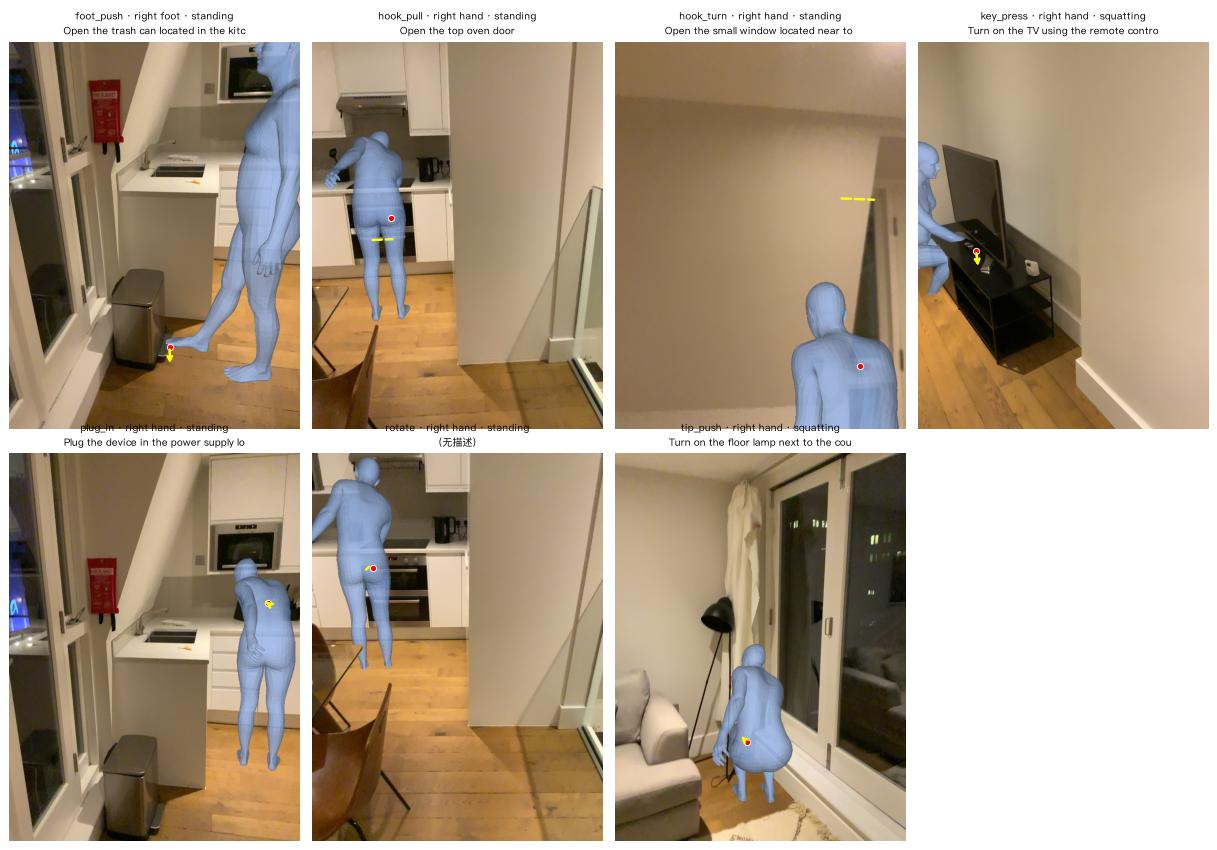

In [4]:
def draw_motion(axis, frame: Frame, e: dict) -> None:
    if e.get("motion_type") is None:
        return
    direction = np.array(e["motion_dir_faro"]) / np.linalg.norm(e["motion_dir_faro"])
    contact = np.array(e["contact_faro"])
    if e["motion_type"] == "trans":
        ends = np.stack([contact, contact + 0.15 * direction])
    else:
        origin = np.array(e["motion_origin_faro"])
        ends = np.stack([origin - 0.12 * direction, origin + 0.12 * direction])
    uv, _, inside = project(ends, frame)
    if inside.all():
        style = dict(arrowstyle="->", color="yellow", lw=2) if e["motion_type"] == "trans" else dict(arrowstyle="-", color="yellow", lw=2, ls="--")
        axis.annotate("", xy=uv[1], xytext=uv[0], arrowprops=style)


composites = []
for e, human in zip(examples, posed):
    frame = frames[e["display_frame"]]
    depth, shade = rasterize(to_camera(human.vertices, frame.cam_to_world), body_model.faces, frame.intrinsics, frame.image_hw)
    composites.append(overlay_body(frame.rgb, frame.depth_m, depth, shade, margin_m=0.05, alpha=0.85))

columns = 4
rows_n = int(np.ceil(len(examples) / columns))
fig, axes = plt.subplots(rows_n, columns, figsize=(3.4 * columns, 4.7 * rows_n))
for axis in axes.flat:
    axis.axis("off")
for axis, e, human, image in zip(axes.flat, examples, posed, composites):
    frame = frames[e["display_frame"]]
    axis.imshow(image)
    uv, _, inside = project(np.array([e["contact_faro"]]), frame)
    if inside[0]:
        axis.plot(*uv[0], "o", color="red", ms=5, mec="white", mew=0.8)
    draw_motion(axis, frame, e)
    axis.set_title(f"{e['action']} · {human.effector} · {human.posture}\n{(e['task'] or '（无描述）')[:38]}", fontsize=8)
plt.tight_layout()
plt.show()

## Step 4 · 检查画面：放进激光扫描（真值，只用于评测）

从侧后上方的虚拟相机看同一个人形（在几个方向里选视线最不被扫描点遮挡的一个）；扫描点为真实颜色，洋红色为真值部件，红点为预测的接触点。人形与真值部件的偏差主要来自 S1-01 中 ARKit 位姿与输入深度的误差。

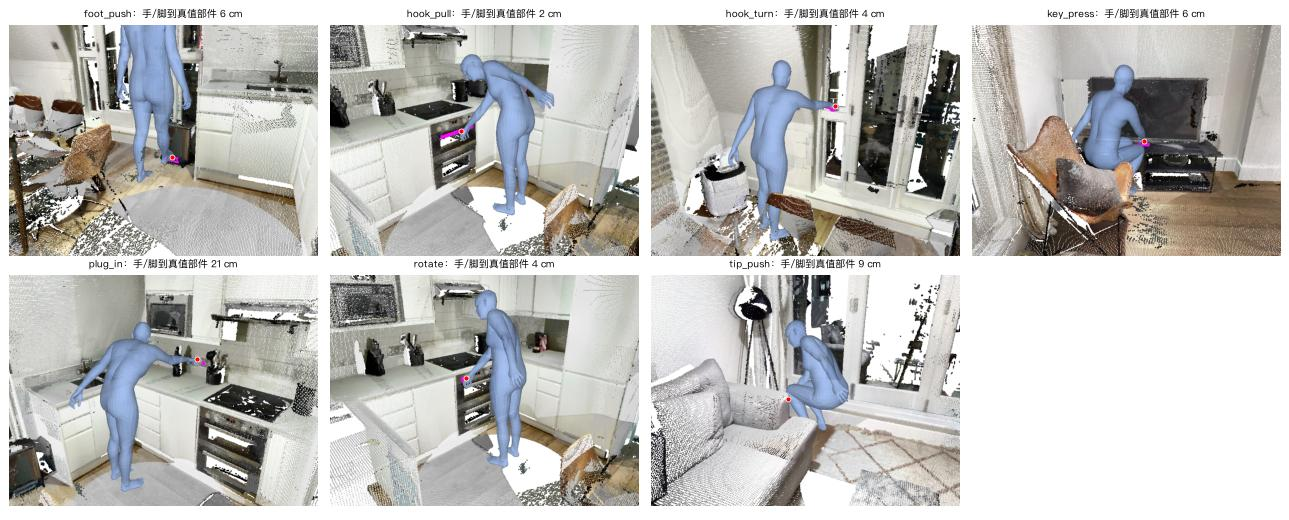

In [5]:
CHECK_HW = (600, 800)
CHECK_K = np.array([[620.0, 0, 399.5], [0, 620.0, 299.5], [0, 0, 1]])


CHECK_DISTANCE_M, CHECK_HEIGHT_M = 2.2, 0.9
CHECK_AZIMUTHS_DEG = (-50, 50, -25, 25, -75, 75, 0)  # around the direction from the part back to the person


def blocked(eye: np.ndarray, centre: np.ndarray) -> int:
    # Scan points close to the line of sight (ignoring the last 0.8 m around the person and the part).
    samples = eye + np.linspace(0.0, 1.0, 30)[:, None] * (centre - eye)
    keep = np.linalg.norm(samples - centre, axis=1) > 0.8
    return sum(len(n) for n in scan_tree.query_ball_point(samples[keep], 0.15))


def check_view(e: dict, human) -> np.ndarray:
    contact, stand = np.array(e["contact_faro"]), np.array(e["stand_faro"])
    centre = 0.5 * (contact + stand) + 0.3 * UP
    back = -np.array(e["facing_faro"])
    eyes = []
    for degrees in CHECK_AZIMUTHS_DEG:
        angle = np.radians(degrees)
        direction = back * np.cos(angle) + np.cross(UP, back) * np.sin(angle)
        eyes.append(centre + CHECK_DISTANCE_M * direction + CHECK_HEIGHT_M * UP)
    eye = min(eyes, key=lambda candidate: blocked(candidate, centre))  # clearest line of sight
    pose = look_at(eye, centre, UP)
    near = scan_tree.query_ball_point(centre, 3.0)
    points = np.vstack([scan_cm[near], part_points[e["annot_id"]]])
    colours = np.vstack([scan_cm_rgb[near], np.tile([1.0, 0.0, 1.0], (len(part_points[e["annot_id"]]), 1))])
    image, scene_depth = splat(to_camera(points, pose), colours, CHECK_K, CHECK_HW, radius_px=1)
    body_depth, shade = rasterize(to_camera(human.vertices, pose), body_model.faces, CHECK_K, CHECK_HW)
    composite = overlay_body((image * 255).astype(np.uint8), np.where(np.isfinite(scene_depth), scene_depth, 0),
                             body_depth, shade, margin_m=0.03, alpha=0.9)
    uv = (to_camera(contact[None], pose) @ CHECK_K.T)
    return composite, uv[0, :2] / uv[0, 2]


fig, axes = plt.subplots(rows_n, columns, figsize=(3.6 * columns, 2.9 * rows_n))
for axis in axes.flat:
    axis.axis("off")
for axis, e, human, row in zip(axes.flat, examples, posed, rows):
    image, contact_uv = check_view(e, human)
    axis.imshow(image)
    axis.plot(*contact_uv, "o", color="red", ms=4, mec="white", mew=0.6)
    axis.set_title(f"{e['action']}：手/脚到真值部件 {row['手掌/脚到真值部件 cm']:.0f} cm", fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
summary = {"examples": len(examples), "median_ik_residual_cm": float(humanoid_table["IK 残差 cm"].median()),
           "median_effector_to_gt_part_cm": float(humanoid_table["手掌/脚到真值部件 cm"].median()),
           "median_feet_to_gt_floor_cm": float(humanoid_table["双脚离真实地面 cm"].median()),
           "median_collision_fraction": float(humanoid_table["身体与扫描冲突"].median())}
(S1 / "humanoid_summary.json").write_text(json.dumps(summary, indent=1))
print(json.dumps(summary, indent=1, ensure_ascii=False))

{
 "examples": 7,
 "median_ik_residual_cm": 3.498220071196556,
 "median_effector_to_gt_part_cm": 5.535542680121741,
 "median_feet_to_gt_floor_cm": 3.643798828125,
 "median_collision_fraction": 0.0
}


### 读结果的方式

- **主画面**看"像不像在操作"：站位、朝向、哪只手、是否下蹲，以及遮挡是否合理。
- **检查画面**和表格看"准不准"：手到真值部件的距离包含 S1-01 的位姿与深度误差；冲突比例高说明站立点或姿态穿进了家具。
- 这是 oracle 版（部件位置与运动轴来自标签），代表展示效果的上限；S1 第 7 步换成预测后再比较。
- 人形是运动学摆放，没有物理和手指动作；旋钮、插头这类需要手指的动作只表现为"手到位"。

### 本次运行记录（2026-11-10）

- **规模：** 7 类动作各一例（pinch_pull、unplug 没有足够像素的部件）。IK 残差中位 3.5 cm。
- **手掌／脚到真值部件的距离：** 烤箱门把手 1.7 cm、烤箱旋钮 3.6 cm、窗把手 4.0 cm、垃圾桶踏板 5.5 cm、遥控器 5.7 cm、落地灯开关 8.6 cm、台面后墙上的插座 21.0 cm。
- **双脚离真实地面：** +1.5 到 +5.7 cm，来自 ARKit 位姿的高度偏差。
- **身体与扫描冲突：** 0–2.9% 的顶点。
- **失败案例：**
  - 墙上插座：站立点退到台面外以后，手够不到，需要更大幅度前倾或侧身。
  - 遥控器：站立点在扫描中不空闲（旁边有椅子）。
  - 窗户和遥控器两例的展示帧里只能看到部分身体。

**下一步：** 走近的短动画（LINGO／DartControl 在远程 A6000 生成，Mac 渲染）；第 6 步按任务描述检索部件与关键帧。